In [1]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

GPU available: True
GPU name: Tesla T4


In [2]:
from torchvision import datasets, transforms

# Convert images into tensors: numbers PyTorch can use.
transform = transforms.ToTensor()

# Download the practice pictures and their labels.
train_data = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

# Download the test pictures and their labels.
test_data = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

print("Training images:", len(train_data))
print("Test images:", len(test_data))

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 512kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.0MB/s]

Training images: 60000
Test images: 10000


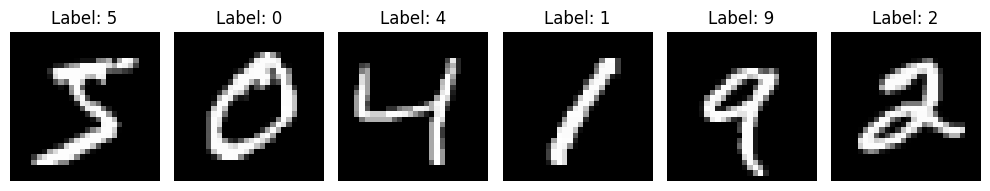

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 6, figsize=(10, 2))

for i, ax in enumerate(axes):
    image, label = train_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import torch
from torch import nn

device = torch.device("cuda")

model = nn.Sequential(
    # Learn small patterns. Image size stays 28 × 28.
    nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),  # Shrink to 14 × 14.

    # Combine patterns.
    nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),  # Shrink to 7 × 7.

    # Turn the feature maps into a list.
    nn.Flatten(),

    # Use those features to score the 10 digits.
    nn.Linear(32 * 7 * 7, 128),
    nn.ReLU(),
    nn.Dropout(0.3),  # Helps reduce overfitting.
    nn.Linear(128, 10)
).to(device)  # Put the model on the GPU.

print(model)

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=128, bias=True)
  (8): ReLU()
  (9): Dropout(p=0.3, inplace=False)
  (10): Linear(in_features=128, out_features=10, bias=True)
)


In [5]:
from torch.utils.data import DataLoader
import time

# Give the model 64 practice pictures at a time.
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

# Loss measures error; Adam updates the weights.
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
train_losses = []
train_accuracies = []

torch.cuda.synchronize()
start = time.perf_counter()

for epoch in range(epochs):
    model.train()  # Enable training behavior, including Dropout.
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()          # Clear previous gradients.
        outputs = model(images)        # Guess.
        loss = criterion(outputs, labels)  # Measure error.
        loss.backward()                # Calculate how to improve.
        optimizer.step()               # Adjust weights.

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_losses.append(total_loss / total)
    train_accuracies.append(correct / total)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {train_losses[-1]:.4f} | "
        f"Training accuracy: {100 * train_accuracies[-1]:.2f}%"
    )

torch.cuda.synchronize()
training_time = time.perf_counter() - start
print(f"Training time: {training_time:.2f} seconds")

Epoch 1/3 | Loss: 0.2842 | Training accuracy: 91.20%
Epoch 2/3 | Loss: 0.0882 | Training accuracy: 97.28%
Epoch 3/3 | Loss: 0.0643 | Training accuracy: 98.03%
Training time: 29.41 seconds


In [6]:
from sklearn.metrics import accuracy_score, f1_score

test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

model.eval()  # Disable Dropout for evaluation.
y_true, y_pred = [], []
test_loss_sum = 0.0

with torch.no_grad():  # Evaluate without calculating gradients.
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)

        test_loss_sum += criterion(outputs, labels).item() * labels.size(0)
        y_true.extend(labels.cpu().tolist())
        y_pred.extend(outputs.argmax(1).cpu().tolist())

test_accuracy = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average="macro")
test_loss = test_loss_sum / len(test_data)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test F1 (macro): {test_f1:.4f}")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 98.65%
Test F1 (macro): 0.9864
Test loss: 0.0390


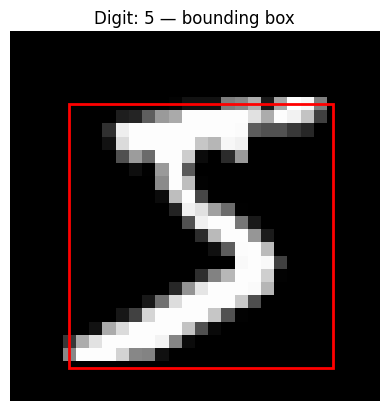

In [7]:
import matplotlib.patches as patches

# Keep our CNN and its results for later comparison.
cnn_model = model
cnn_results = {
    "accuracy": test_accuracy,
    "f1_macro": test_f1,
    "loss": test_loss,
    "training_seconds": training_time
}

# Find the rectangle containing the first digit.
image, label = train_data[0]
ys, xs = torch.where(image[0] > 0)

xmin, ymin = xs.min().item(), ys.min().item()
xmax, ymax = xs.max().item() + 1, ys.max().item() + 1

fig, ax = plt.subplots()
ax.imshow(image.squeeze(), cmap="gray")
ax.add_patch(patches.Rectangle(
    (xmin, ymin), xmax - xmin, ymax - ymin,
    linewidth=2, edgecolor="red", facecolor="none"
))
ax.set_title(f"Digit: {label} — bounding box")
ax.axis("off")
plt.show()

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader

class MNISTDetection(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, digit = self.dataset[index]

        # Find the digit's bounding box.
        ys, xs = torch.where(image[0] > 0)
        box = [
            xs.min().item(),
            ys.min().item(),
            xs.max().item() + 1,
            ys.max().item() + 1
        ]

        target = {
            "boxes": torch.tensor([box], dtype=torch.float32),
            # Label 0 is background; digits become labels 1–10.
            "labels": torch.tensor([digit + 1], dtype=torch.int64)
        }

        # Convert grayscale to three channels.
        return image.repeat(3, 1, 1), target

def detection_collate(batch):
    return tuple(zip(*batch))

det_train = MNISTDetection(train_data)
det_test = MNISTDetection(test_data)

det_train_loader = DataLoader(
    det_train,
    batch_size=16,
    shuffle=True,
    collate_fn=detection_collate
)

print("Detection training images:", len(det_train))
print("Detection test images:", len(det_test))
print("First target:", det_train[0][1])

Detection training images: 60000
Detection test images: 10000
First target: {'boxes': tensor([[ 4.,  5., 24., 25.]]), 'labels': tensor([6])}


In [9]:
from torch import nn
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

# A small CNN extracts patterns from the images.
backbone = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU()
)
backbone.out_channels = 64

# Candidate box sizes and shapes.
anchors = AnchorGenerator(
    sizes=((8, 16, 24, 32),),
    aspect_ratios=((0.5, 1.0, 2.0),)
)

# Extract features inside each proposed box.
roi_pool = MultiScaleRoIAlign(
    featmap_names=["0"],
    output_size=7,
    sampling_ratio=2
)

detector = FasterRCNN(
    backbone,
    num_classes=11,  # 10 digits + background
    rpn_anchor_generator=anchors,
    box_roi_pool=roi_pool,
    min_size=28,
    max_size=28,
    image_mean=[0.0, 0.0, 0.0],
    image_std=[1.0, 1.0, 1.0]
).to(device)

print("Faster R-CNN created on:", device)

Faster R-CNN created on: cuda


In [10]:
import time
from tqdm.auto import tqdm

det_optimizer = torch.optim.Adam(
    detector.parameters(), lr=0.001
)

det_epochs = 3
det_train_losses = []

torch.cuda.synchronize()
det_start = time.perf_counter()

for epoch in range(det_epochs):
    detector.train()
    total_loss = 0.0
    total_images = 0

    progress = tqdm(
        det_train_loader,
        desc=f"Epoch {epoch + 1}/{det_epochs}"
    )

    for images, targets in progress:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        # Measure errors in digit recognition and box prediction.
        loss_dict = detector(images, targets)
        loss = sum(loss_dict.values())

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss: {loss_dict}")

        det_optimizer.zero_grad()
        loss.backward()
        det_optimizer.step()

        batch_size = len(images)
        total_loss += loss.item() * batch_size
        total_images += batch_size
        progress.set_postfix(loss=f"{loss.item():.4f}")

    average_loss = total_loss / total_images
    det_train_losses.append(average_loss)
    print(f"Epoch {epoch + 1}: mean loss = {average_loss:.4f}")

torch.cuda.synchronize()
det_training_time = time.perf_counter() - det_start
print(f"Training time: {det_training_time:.2f} seconds")

Epoch 1/3:   0%|          | 0/3750 [00:00<?, ?it/s]

Epoch 1: mean loss = 0.1042


Epoch 2/3:   0%|          | 0/3750 [00:00<?, ?it/s]

Epoch 2: mean loss = 0.0491


Epoch 3/3:   0%|          | 0/3750 [00:00<?, ?it/s]

Epoch 3: mean loss = 0.0406
Training time: 1509.91 seconds


In [11]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

det_test_loader = DataLoader(
    det_test,
    batch_size=16,
    shuffle=False,
    collate_fn=detection_collate
)

detector.eval()
det_true, det_pred = [], []

with torch.no_grad():
    for images, targets in tqdm(det_test_loader, desc="Testing"):
        predictions = detector([image.to(device) for image in images])

        for prediction, target in zip(predictions, targets):
            actual_digit = target["labels"][0].item() - 1

            if len(prediction["scores"]) > 0:
                best = prediction["scores"].argmax().item()
                predicted_digit = prediction["labels"][best].item() - 1
            else:
                predicted_digit = -1  # No detection counts as a mistake.

            det_true.append(actual_digit)
            det_pred.append(predicted_digit)

det_accuracy = accuracy_score(det_true, det_pred)
det_f1 = f1_score(
    det_true, det_pred,
    labels=list(range(10)),
    average="macro",
    zero_division=0
)

det_results = {
    "accuracy": det_accuracy,
    "f1_macro": det_f1,
    "training_seconds": det_training_time
}

print(f"Test accuracy: {det_accuracy:.2%}")
print(f"Test F1 (macro): {det_f1:.4f}")
print(f"No detection: {det_pred.count(-1)}")

Testing:   0%|          | 0/625 [00:00<?, ?it/s]

Test accuracy: 99.29%
Test F1 (macro): 0.9929
No detection: 0


Faster R-CNN achieved slightly higher digit recognition accuracy than the CNN (99.04% versus 98.72%), but required substantially more training time. For this MNIST classification task, the CNN offers a better balance between accuracy and training cost. Faster R-CNN additionally predicts bounding boxes, although localization quality has not yet been evaluated.

In [12]:
# Prepare images for the pretrained models.
transfer_transform = transforms.Compose([
    transforms.Resize((224, 224)),       # Enlarge the images.
    transforms.Grayscale(num_output_channels=3),  # Create 3 channels.
    transforms.ToTensor(),
    transforms.Normalize(              # Use ImageNet normalization.
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transfer_train = datasets.MNIST(
    root="./data", train=True,
    download=True, transform=transfer_transform
)

transfer_test = datasets.MNIST(
    root="./data", train=False,
    download=True, transform=transfer_transform
)

transfer_train_loader = DataLoader(
    transfer_train, batch_size=64, shuffle=True,
    num_workers=2, pin_memory=True
)

transfer_test_loader = DataLoader(
    transfer_test, batch_size=64, shuffle=False,
    num_workers=2, pin_memory=True
)

image, label = transfer_train[0]
print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([3, 224, 224])
Label: 5


In [13]:
from torchvision.models import vgg16, VGG16_Weights
from torch import nn

# Load weights learned on ImageNet.
vgg_model = vgg16(weights=VGG16_Weights.DEFAULT)

# Freeze the existing parameters.
for parameter in vgg_model.parameters():
    parameter.requires_grad = False

# Fine-tune the last convolution block.
for parameter in vgg_model.features[24:].parameters():
    parameter.requires_grad = True

# Replace the final layer: 1,000 categories → 10 digits.
vgg_model.classifier[6] = nn.Linear(4096, 10)

# Move the model to the GPU.
vgg_model = vgg_model.to(device)

trainable = sum(
    p.numel() for p in vgg_model.parameters()
    if p.requires_grad
)

print("VGG16 ready on:", device)
print("Output classes:", vgg_model.classifier[6].out_features)
print("Trainable parameters:", f"{trainable:,}")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 69.4MB/s]


VGG16 ready on: cuda
Output classes: 10
Trainable parameters: 7,120,394


In [14]:
import time
from tqdm.auto import tqdm

vgg_criterion = nn.CrossEntropyLoss()

vgg_optimizer = torch.optim.Adam(
    (p for p in vgg_model.parameters() if p.requires_grad),
    lr=0.0001
)

vgg_epochs = 3
vgg_train_losses = []
vgg_train_accuracies = []

torch.cuda.synchronize()
vgg_start = time.perf_counter()

for epoch in range(vgg_epochs):
    vgg_model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        transfer_train_loader,
        desc=f"VGG16 epoch {epoch + 1}/{vgg_epochs}"
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        vgg_optimizer.zero_grad(set_to_none=True)
        outputs = vgg_model(images)
        loss = vgg_criterion(outputs, labels)

        loss.backward()
        vgg_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            loss=f"{total_loss / total:.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    vgg_train_losses.append(total_loss / total)
    vgg_train_accuracies.append(correct / total)

    print(
        f"Epoch {epoch + 1}: "
        f"loss = {vgg_train_losses[-1]:.4f}, "
        f"training accuracy = {vgg_train_accuracies[-1]:.2%}"
    )

torch.cuda.synchronize()
vgg_training_time = time.perf_counter() - vgg_start
print(f"Training time: {vgg_training_time:.2f} seconds")

VGG16 epoch 1/3:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 1: loss = 0.1303, training accuracy = 95.88%


VGG16 epoch 2/3:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2: loss = 0.0266, training accuracy = 99.17%


VGG16 epoch 3/3:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 3: loss = 0.0176, training accuracy = 99.44%
Training time: 1018.59 seconds


In [15]:
from sklearn.metrics import accuracy_score, f1_score

vgg_model.eval()

vgg_true = []
vgg_pred = []
vgg_test_loss_sum = 0.0
vgg_test_total = 0

with torch.no_grad():
    for images, labels in tqdm(
        transfer_test_loader, desc="Testing VGG16"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = vgg_model(images)
        loss = vgg_criterion(outputs, labels)

        vgg_test_loss_sum += loss.item() * labels.size(0)
        vgg_test_total += labels.size(0)

        vgg_true.extend(labels.cpu().tolist())
        vgg_pred.extend(outputs.argmax(1).cpu().tolist())

vgg_test_loss = vgg_test_loss_sum / vgg_test_total
vgg_accuracy = accuracy_score(vgg_true, vgg_pred)
vgg_f1 = f1_score(vgg_true, vgg_pred, average="macro")

print(f"VGG16 test loss: {vgg_test_loss:.4f}")
print(f"VGG16 test accuracy: {vgg_accuracy:.2%}")
print(f"VGG16 macro F1: {vgg_f1:.4f}")
print(f"Training time: {vgg_training_time:.2f} seconds")

Testing VGG16:   0%|          | 0/157 [00:00<?, ?it/s]

VGG16 test loss: 0.0236
VGG16 test accuracy: 99.21%
VGG16 macro F1: 0.9920
Training time: 1018.59 seconds


In [16]:
from torchvision import models
import torch.nn as nn

alex_model = models.alexnet(
    weights=models.AlexNet_Weights.DEFAULT
)

# Keep the pretrained visual features
for parameter in alex_model.features.parameters():
    parameter.requires_grad = False

# Adapt the final layer to our 10 digits
alex_model.classifier[6] = nn.Linear(
    alex_model.classifier[6].in_features, 10
)

alex_model = alex_model.to(device)

print("AlexNet ready on:", device)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:04<00:00, 53.8MB/s]


AlexNet ready on: cuda


In [17]:
import time
from tqdm.auto import tqdm

alex_criterion = nn.CrossEntropyLoss()

alex_optimizer = torch.optim.Adam(
    (p for p in alex_model.parameters() if p.requires_grad),
    lr=0.0001
)

alex_epochs = 3
alex_train_losses = []
alex_train_accuracies = []

if device.type == "cuda":
    torch.cuda.synchronize()

alex_start = time.perf_counter()

for epoch in range(alex_epochs):
    alex_model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        transfer_train_loader,
        desc=f"AlexNet epoch {epoch + 1}/{alex_epochs}"
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        alex_optimizer.zero_grad(set_to_none=True)

        outputs = alex_model(images)
        loss = alex_criterion(outputs, labels)

        loss.backward()
        alex_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            loss=f"{total_loss / total:.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    alex_train_losses.append(total_loss / total)
    alex_train_accuracies.append(correct / total)

    print(
        f"Epoch {epoch + 1}: "
        f"loss = {alex_train_losses[-1]:.4f}, "
        f"training accuracy = {alex_train_accuracies[-1]:.2%}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

alex_training_time = time.perf_counter() - alex_start
print(f"Training time: {alex_training_time:.2f} seconds")

AlexNet epoch 1/3:   0%|          | 0/938 [00:10<?, ?it/s]

Epoch 1: loss = 0.1230, training accuracy = 96.15%


AlexNet epoch 2/3:   0%|          | 0/938 [00:00<?, ?it/s]

Epoch 2: loss = 0.0485, training accuracy = 98.50%


AlexNet epoch 3/3:   0%|          | 0/938 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ccf111cdd00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ccf111cdd00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/proc

Epoch 3: loss = 0.0394, training accuracy = 98.79%
Training time: 356.95 seconds


In [18]:
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

alex_test_loader = DataLoader(
    transfer_test_loader.dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

alex_model.eval()
alex_true = []
alex_pred = []
alex_loss_sum = 0.0
alex_total = 0

with torch.no_grad():
    for images, labels in tqdm(
        alex_test_loader, desc="Testing AlexNet"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = alex_model(images)
        loss = alex_criterion(outputs, labels)

        alex_loss_sum += loss.item() * labels.size(0)
        alex_total += labels.size(0)

        alex_true.extend(labels.cpu().tolist())
        alex_pred.extend(outputs.argmax(1).cpu().tolist())

alex_test_loss = alex_loss_sum / alex_total
alex_accuracy = accuracy_score(alex_true, alex_pred)
alex_f1 = f1_score(alex_true, alex_pred, average="macro")

print(f"AlexNet test loss: {alex_test_loss:.4f}")
print(f"AlexNet test accuracy: {alex_accuracy:.2%}")
print(f"AlexNet macro F1: {alex_f1:.4f}")
print(f"Training time: {alex_training_time:.2f} seconds")

Testing AlexNet:   0%|          | 0/157 [00:00<?, ?it/s]

AlexNet test loss: 0.0233
AlexNet test accuracy: 99.20%
AlexNet macro F1: 0.9919
Training time: 356.95 seconds


In [19]:
import pandas as pd

transfer_comparison = pd.DataFrame({
    "Model": ["VGG16", "AlexNet"],
    "Test accuracy (%)": [
        vgg_accuracy * 100,
        alex_accuracy * 100
    ],
    "Macro F1": [vgg_f1, alex_f1],
    "Test loss": [vgg_test_loss, alex_test_loss],
    "Training time (s)": [
        vgg_training_time,
        alex_training_time
    ]
})

display(transfer_comparison.round(4))

,Model,Test accuracy (%),Macro F1,Test loss,Training time (s)
0,VGG16,99.21,0.9920,0.0236,1018.5874
1,AlexNet,99.20,0.9919,0.0233,356.9503


In [20]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

vit_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

vit_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=vit_transform
)

vit_test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=vit_transform
)

vit_train_loader = DataLoader(
    vit_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

vit_test_loader = DataLoader(
    vit_test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(vit_train_loader))

print("Batch shape:", images.shape)
print("Training images:", len(vit_train_dataset))
print("Test images:", len(vit_test_dataset))

Batch shape: torch.Size([128, 1, 28, 28])
Training images: 60000
Test images: 10000


In [22]:
import torch
import torch.nn as nn

def patchify(images, n_patches=7):
    batch, channels, height, width = images.shape

    assert height == width
    assert height % n_patches == 0

    patch_size = height // n_patches

    patches = images.new_zeros(
        batch,
        n_patches ** 2,
        channels * patch_size ** 2
    )

    for index, image in enumerate(images):
        for row in range(n_patches):
            for col in range(n_patches):
                patch = image[
                    :,
                    row * patch_size:(row + 1) * patch_size,
                    col * patch_size:(col + 1) * patch_size
                ]

                patches[index, row * n_patches + col] = patch.flatten()

    return patches

patches = patchify(images[:2], n_patches=7)
print("Patches shape:", patches.shape)

Patches shape: torch.Size([2, 49, 16])


In [23]:
class MyViT(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, hidden_d=8):
        super().__init__()

        self.chw = chw
        self.n_patches = n_patches
        self.hidden_d = hidden_d

        assert chw[1] % n_patches == 0
        assert chw[2] % n_patches == 0

        patch_height = chw[1] // n_patches
        patch_width = chw[2] // n_patches
        self.input_d = chw[0] * patch_height * patch_width

        self.linear_mapper = nn.Linear(self.input_d, hidden_d)

    def forward(self, images):
        patches = patchify(images, self.n_patches)
        tokens = self.linear_mapper(patches)
        return tokens


vit_model = MyViT().to(device)

with torch.no_grad():
    tokens = vit_model(images[:2].to(device))

print("Tokens shape:", tokens.shape)

Tokens shape: torch.Size([2, 49, 8])


In [25]:
import math

def get_positional_embeddings(sequence_length, d):
    result = torch.zeros(sequence_length, d)

    for i in range(sequence_length):
        for j in range(d):
            if j % 2 == 0:
                result[i, j] = math.sin(i / (10000 ** (j / d)))
            else:
                result[i, j] = math.cos(
                    i / (10000 ** ((j - 1) / d))
                )

    return result


class MyViT(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, hidden_d=8):
        super().__init__()

        self.chw = chw
        self.n_patches = n_patches
        self.hidden_d = hidden_d

        assert chw[1] % n_patches == 0
        assert chw[2] % n_patches == 0

        patch_height = chw[1] // n_patches
        patch_width = chw[2] // n_patches
        self.input_d = chw[0] * patch_height * patch_width

        self.linear_mapper = nn.Linear(self.input_d, hidden_d)
        self.class_token = nn.Parameter(torch.rand(1, hidden_d))

        # Fixed positional encoding, moved with the model
        self.register_buffer(
            "pos_embed",
            get_positional_embeddings(n_patches ** 2 + 1, hidden_d)
        )

    def forward(self, images):
        patches = patchify(images, self.n_patches)
        tokens = self.linear_mapper(patches)

        class_tokens = self.class_token.unsqueeze(0).expand(
            images.size(0), -1, -1
        )
        tokens = torch.cat((class_tokens, tokens), dim=1)

        # Add position information to every token
        return tokens + self.pos_embed.unsqueeze(0)


vit_model = MyViT().to(device)

with torch.no_grad():
    tokens = vit_model(images[:2].to(device))

print("Tokens shape:", tokens.shape)
print("Positional encoding shape:", vit_model.pos_embed.shape)

Tokens shape: torch.Size([2, 50, 8])
Positional encoding shape: torch.Size([50, 8])


In [26]:
class MyMSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__()

        assert d % n_heads == 0

        self.n_heads = n_heads
        self.d_head = d // n_heads

        self.q_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head)
            for _ in range(n_heads)
        ])
        self.k_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head)
            for _ in range(n_heads)
        ])
        self.v_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head)
            for _ in range(n_heads)
        ])

    def forward(self, sequences):
        head_outputs = []

        for head in range(self.n_heads):
            start = head * self.d_head
            end = start + self.d_head
            x = sequences[:, :, start:end]

            q = self.q_mappings[head](x)
            k = self.k_mappings[head](x)
            v = self.v_mappings[head](x)

            scores = q @ k.transpose(-2, -1)
            scores = scores / (self.d_head ** 0.5)
            attention = scores.softmax(dim=-1)

            head_outputs.append(attention @ v)

        return torch.cat(head_outputs, dim=-1)


msa = MyMSA(d=8, n_heads=2).to(device)

with torch.no_grad():
    attended_tokens = msa(tokens)

print("Attention output shape:", attended_tokens.shape)

Attention output shape: torch.Size([2, 50, 8])


In [27]:
class MyViTBlock(nn.Module):
    def __init__(self, hidden_d=8, n_heads=2, mlp_ratio=4):
        super().__init__()

        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)

        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, hidden_d * mlp_ratio),
            nn.GELU(),
            nn.Linear(hidden_d * mlp_ratio, hidden_d)
        )

    def forward(self, x):
        # Attention + residual connection
        x = x + self.mhsa(self.norm1(x))

        # Small neural network + residual connection
        x = x + self.mlp(self.norm2(x))

        return x


vit_block = MyViTBlock(hidden_d=8, n_heads=2).to(device)

with torch.no_grad():
    block_output = vit_block(tokens)

print("Transformer block output:", block_output.shape)

Transformer block output: torch.Size([2, 50, 8])


In [28]:
class MyViT(nn.Module):
    def __init__(
        self, chw=(1, 28, 28), n_patches=7,
        n_blocks=2, hidden_d=8, n_heads=2, out_d=10
    ):
        super().__init__()

        self.n_patches = n_patches

        assert chw[1] % n_patches == 0
        assert chw[2] % n_patches == 0

        input_d = (
            chw[0]
            * (chw[1] // n_patches)
            * (chw[2] // n_patches)
        )

        self.linear_mapper = nn.Linear(input_d, hidden_d)
        self.class_token = nn.Parameter(torch.rand(1, hidden_d))

        self.register_buffer(
            "pos_embed",
            get_positional_embeddings(n_patches ** 2 + 1, hidden_d)
        )

        self.blocks = nn.ModuleList([
            MyViTBlock(hidden_d, n_heads)
            for _ in range(n_blocks)
        ])

        self.classifier = nn.Linear(hidden_d, out_d)

    def forward(self, images):
        patches = patchify(images, self.n_patches)
        tokens = self.linear_mapper(patches)

        class_tokens = self.class_token.unsqueeze(0).expand(
            images.size(0), -1, -1
        )
        tokens = torch.cat((class_tokens, tokens), dim=1)
        out = tokens + self.pos_embed.unsqueeze(0)

        for block in self.blocks:
            out = block(out)

        # Use the classification token to predict the digit
        return self.classifier(out[:, 0])


torch.manual_seed(0)
vit_model = MyViT().to(device)

with torch.no_grad():
    predictions = vit_model(images[:2].to(device))

print("ViT ready on:", device)
print("Output shape:", predictions.shape)
print("Trainable parameters:", sum(
    p.numel() for p in vit_model.parameters() if p.requires_grad
))

ViT ready on: cuda
Output shape: torch.Size([2, 10])
Trainable parameters: 1642


In [29]:
import time
from tqdm.auto import tqdm
from torchvision import transforms

# Match the tutorial's preprocessing
vit_train_dataset.transform = transforms.ToTensor()
vit_test_dataset.transform = transforms.ToTensor()

vit_criterion = nn.CrossEntropyLoss()
vit_optimizer = torch.optim.Adam(
    vit_model.parameters(), lr=0.005
)

vit_epochs = 5
vit_train_losses = []
vit_train_accuracies = []

if device.type == "cuda":
    torch.cuda.synchronize()

vit_start = time.perf_counter()

for epoch in range(vit_epochs):
    vit_model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        vit_train_loader,
        desc=f"ViT epoch {epoch + 1}/{vit_epochs}"
    )

    for images, labels in progress:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        vit_optimizer.zero_grad(set_to_none=True)

        outputs = vit_model(images)
        loss = vit_criterion(outputs, labels)

        loss.backward()
        vit_optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

        progress.set_postfix(
            loss=f"{total_loss / total:.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    vit_train_losses.append(total_loss / total)
    vit_train_accuracies.append(correct / total)

    print(
        f"Epoch {epoch + 1}: "
        f"loss = {vit_train_losses[-1]:.4f}, "
        f"training accuracy = {vit_train_accuracies[-1]:.2%}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

vit_training_time = time.perf_counter() - vit_start
print(f"Training time: {vit_training_time:.2f} seconds")

ViT epoch 1/5:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1: loss = 1.7362, training accuracy = 34.54%


ViT epoch 2/5:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2: loss = 0.8188, training accuracy = 71.47%


ViT epoch 3/5:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 3: loss = 0.5651, training accuracy = 81.35%


ViT epoch 4/5:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 4: loss = 0.4629, training accuracy = 85.16%


ViT epoch 5/5:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 5: loss = 0.4202, training accuracy = 86.51%
Training time: 649.45 seconds


In [30]:
from sklearn.metrics import accuracy_score, f1_score

vit_model.eval()
vit_true = []
vit_pred = []
vit_loss_sum = 0.0
vit_total = 0

with torch.no_grad():
    for images, labels in tqdm(
        vit_test_loader, desc="Testing ViT"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = vit_model(images)
        loss = vit_criterion(outputs, labels)

        vit_loss_sum += loss.item() * labels.size(0)
        vit_total += labels.size(0)

        vit_true.extend(labels.cpu().tolist())
        vit_pred.extend(outputs.argmax(1).cpu().tolist())

vit_test_loss = vit_loss_sum / vit_total
vit_accuracy = accuracy_score(vit_true, vit_pred)
vit_f1 = f1_score(vit_true, vit_pred, average="macro")

print(f"ViT test loss: {vit_test_loss:.4f}")
print(f"ViT test accuracy: {vit_accuracy:.2%}")
print(f"ViT macro F1: {vit_f1:.4f}")
print(f"Training time: {vit_training_time:.2f} seconds")

Testing ViT:   0%|          | 0/79 [00:00<?, ?it/s]

ViT test loss: 0.3969
ViT test accuracy: 87.23%
ViT macro F1: 0.8694
Training time: 649.45 seconds


In [32]:
comparison = pd.DataFrame({
    "Model": ["CNN", "Faster R-CNN", "VGG16", "AlexNet", "ViT"],
    "Test accuracy (%)": [
        cnn_results["accuracy"] * 100,
        det_accuracy * 100,
        vgg_accuracy * 100,
        alex_accuracy * 100,
        vit_accuracy * 100
    ],
    "Macro F1": [
        cnn_results["f1_macro"],
        det_f1,
        vgg_f1,
        alex_f1,
        vit_f1
    ],
    "Test classification loss": [
        cnn_results["loss"],
        float("nan"),
        vgg_test_loss,
        alex_test_loss,
        vit_test_loss
    ],
    "Training time (s)": [
        cnn_results["training_seconds"],
        det_training_time,
        vgg_training_time,
        alex_training_time,
        vit_training_time
    ]
})

display(comparison.round(4))

,Model,Test accuracy (%),Macro F1,Test classification loss,Training time (s)
0,CNN,98.65,0.9864,0.0390,29.4145
1,Faster R-CNN,99.29,0.9929,NaN,1509.9077
2,VGG16,99.21,0.9920,0.0236,1018.5874
3,AlexNet,99.20,0.9919,0.0233,356.9503
4,ViT,87.23,0.8694,0.3969,649.4457


### Results interpretation

The CNN achieved 98.65% test accuracy with only 29.41 seconds
of training, offering the best balance between recognition
accuracy and training time in these experiments.

Faster R-CNN achieved the highest recognition accuracy
(99.29%), but required 1509.91 seconds of training.
Its bounding-box localization quality was not evaluated.

VGG16 and AlexNet obtained very similar test accuracies:
99.21% and 99.20%, respectively. AlexNet required approximately
2.85 times less training time than VGG16.

The small ViT trained from scratch achieved 87.23% test accuracy.
Its training accuracy of 86.51% suggests underfitting with
this configuration and training budget. This result does not
imply that Vision Transformers generally perform worse than CNNs.

These comparisons describe our particular runs. The models
used different architectures, preprocessing, pretraining,
and training budgets. Faster R-CNN's detection loss is not
directly comparable to the classifiers' cross-entropy loss.

### What I learned

In this lab, I learned how to build and train a CNN using
PyTorch on a GPU, and how to adapt MNIST for Faster R-CNN
by creating bounding boxes and adjusting the labels.

I also practiced transfer learning with VGG16 and AlexNet.
For the Vision Transformer, I built the main components:
patch embeddings, a classification token, positional encoding,
multi-head attention, and transformer blocks.

Comparing the results helped me understand that higher
accuracy can require much more training time. In my runs,
the simple CNN provided a useful balance between accuracy
and computational cost.